# Model comparison for the SPX surface behind the Athena autocall
**Question.** Heston misses the short-dated skew. Where exactly is the calibration error, and which model brings both the vol error and the price error down without hurting the strikes and dates the note depends on?

**Set-up.** Live SPX snapshot of 30 September 2026, 15:22 EDT (spot 7,696.50), the same quote filter and objective as `main.ipynb`, and the v1 expiry rule: 1M, 3M, 6M and then the semi-annual product dates, each mapped to the nearest listed expiry. Every model is fitted to **all eight expiries** with the same objective (spread-weighted implied-vol RMSE, one vote per expiry), so the comparison is like for like. Errors are then reported split into the short end (1M, 3M) and 6M+.

**Models.**
| Model | Parameters | What it adds | Reference |
|---|---|---|---|
| Heston | 5 | baseline | Heston (1993) |
| Bates | 8 | lognormal jumps in the spot: a skew at 1M that a diffusion cannot produce | Bates (1996) |
| Double Heston | 10 | a second variance factor: independent short and long vol dynamics | Christoffersen, Heston, Jacobs (2009) |
| Rough Heston | 6 | a fractional kernel (Hurst $H<1/2$): power-law ATM skew $\propto T^{H-1/2}$ | El Euch, Rosenbaum (2019); Gatheral, Radoičić (2019) |

Heston, Bates and double Heston are also simulated (Andersen's QE scheme, extended with jumps and with two factors) so the note can be priced under each. Rough Heston is compared on the surface fit only: its Monte Carlo needs the hybrid scheme of Bennedsen, Lunde and Pakkanen (2017) or the lifted-Heston Markovian approximation of Abi Jaber (2019), which are outside this notebook.


## 1. Theory

### Heston (baseline)
$dS_t = (r-q)S_t\,dt + \sqrt{V_t}\,S_t\,dW_t,\qquad dV_t = \kappa(\theta - V_t)\,dt + \sigma\sqrt{V_t}\,dB_t,\qquad d\langle W,B\rangle_t = \rho\,dt.$

Characteristic function of $X_T=\log(S_T/S_0)$ in the stable ("little trap") form, with $\xi=\kappa-\sigma\rho iu$, $d=\sqrt{\xi^2+\sigma^2(u^2+iu)}$, $g=(\xi-d)/(\xi+d)$:
$$\phi(u)=\exp\Big(iu(r-q)T+\frac{\kappa\theta}{\sigma^2}\big[(\xi-d)T-2\log\frac{1-ge^{-dT}}{1-g}\big]+\frac{V_0}{\sigma^2}\frac{(\xi-d)(1-e^{-dT})}{1-ge^{-dT}}\Big).$$
Five parameters for a whole surface: the vol-of-vol $\sigma$ has to produce both the short-dated skew (which really needs jumps) and the long-dated curvature, and the calibration compromises.

### Bates: Heston with jumps
$\frac{dS_t}{S_t} = (r-q-\lambda\bar k)\,dt + \sqrt{V_t}\,dW_t + (e^{J}-1)\,dN_t,\qquad N_t\sim\text{Poisson}(\lambda t),\ J\sim N(\mu_J,\sigma_J^2),\ \bar k = e^{\mu_J+\sigma_J^2/2}-1.$

The jump part is independent of the diffusion, so the characteristic function multiplies:
$$\phi_{\text{Bates}}(u)=\phi_{\text{Heston}}(u)\,\exp\Big(\lambda T\big(e^{iu\mu_J-u^2\sigma_J^2/2}-1\big)-iu\lambda T\bar k\Big).$$
A negative mean jump makes deep short-dated puts expensive at once, without a huge $\sigma$; the compensator $\lambda\bar k$ keeps the forward exact. In the Monte Carlo the jumps are added to the QE log-spot step: $N\sim\text{Poisson}(\lambda\Delta)$ jumps of total size $N\mu_J+\sigma_J\sqrt N\,Z$, with $-\lambda\bar k\Delta$ in the drift.

### Double Heston
$dS_t/S_t=(r-q)dt+\sqrt{V_{1,t}}\,dW_{1,t}+\sqrt{V_{2,t}}\,dW_{2,t}$, each $V_i$ a CIR process with its own $(\kappa_i,\theta_i,\sigma_i,\rho_i,V_{i,0})$ and independent of the other. The characteristic function is the product of two Heston factors sharing one drift term. Typically one factor is fast ($\kappa$ large, drives the short end) and one slow (drives the long end), which is why the model can fit a term structure of skew that a single factor cannot. Simulation: two QE variance steps and one log-spot step whose drift and variance terms are the sums of the two factors' terms (the martingale correction applies factor by factor).

### Rough Heston
$$V_t=V_0+\frac{1}{\Gamma(\alpha)}\int_0^t (t-s)^{\alpha-1}\Big[\kappa(\theta-V_s)\,ds+\sigma\sqrt{V_s}\,dB_s\Big],\qquad \alpha=H+\tfrac12,\ H\in(0,\tfrac12).$$
Realised volatility behaves like a fractional process with $H\approx0.1$ (Gatheral, Jaisson, Rosenbaum 2018), and such a kernel makes the ATM skew explode like $T^{H-1/2}$ at short maturities, which is the empirical power law. El Euch and Rosenbaum (2019) showed the model keeps an affine structure:
$$E\big[e^{aX_T}\big]=\exp\Big(\kappa\theta\, I^{1}h(a,T)+V_0\, I^{1-\alpha}h(a,T)\Big),\qquad D^{\alpha}h=\tfrac12(a^2-a)+(a\rho\sigma-\kappa)\,h+\tfrac{\sigma^2}{2}h^2,\ h(a,0)=0,$$
with $I^{r}$ the fractional integral and $D^\alpha$ the fractional derivative; $H=\tfrac12$ gives back Heston exactly. The fractional Riccati has no closed form. Solving it numerically for 4,096 frequencies per expiry is far too slow for a global calibration, so we use the rational approximation of Gatheral and Radoičić (2019): in $x=t^\alpha$,
$$h(a,t)\approx\frac{p_1x+p_2x^2+p_3x^3}{1+q_1x+q_2x^2+q_3x^3},$$
with the six coefficients fixed by the first three terms of the short-time series $h=\sum\beta_k t^{k\alpha}$ and the first three terms of the long-time expansion $h=r_-+\gamma_1t^{-\alpha}+\gamma_2t^{-2\alpha}+\dots$ ($r_-$ the stable root of the quadratic). The two fractional integrals are then Gauss-Jacobi quadratures after the substitution $s=Tv^{1/\alpha}$, which turns the integrand into a smooth function of $v$. The approximant is checked below against a fractional Adams solver (Diethelm, Ford, Freed 2002). The rough model calibrates as fast as Heston this way.

### Objective and metrics
Objective for every model: $\sqrt{\sum_i w_i(\sigma_i^{\text{model}}-\sigma_i^{\text{mkt}})^2}$ with $w_i\propto 1/\max(\text{bid-ask spread}_i\text{ in vol},\,0.5\%)^2$, normalised so each expiry has total weight one. Reported metrics: unweighted implied-vol RMSE (vol points) and price RMSE (index points), each on all quotes, on the short end ($T<6$M) and on 6M+; the largest single vol miss; and the mean absolute vol error at the product strikes (1Y to 4Y, 60% to 100%). Global search: differential evolution (seed 42, population 15 per parameter) followed by L-BFGS-B.

**References.** Heston (1993) RFS 6; Bates (1996) RFS 9; Christoffersen, Heston, Jacobs (2009) Management Science 55; Gatheral, Jaisson, Rosenbaum (2018) Quant. Finance 18; El Euch, Rosenbaum (2019) Math. Finance 29; Gatheral, Radoičić (2019) IJTAF 22; Abi Jaber (2019) Quant. Finance 19; Andersen (2008) J. Comp. Finance 11; Bennedsen, Lunde, Pakkanen (2017) Finance & Stochastics 21; Diethelm, Ford, Freed (2002) Nonlinear Dynamics 29.


In [1]:
import numpy as np, pandas as pd, time
from datetime import datetime, timedelta
import matplotlib.pyplot as plt
import heston_pricer as hp
from heston_pricer import (rate_curve_func, set_rate_curve, OISBootstrapper, attach_quote_details, filter_call_spread_arbitrage,
                           implied_vol_call_vec, HestonAutocallPricer)
from vol_models import (HestonModel, BatesModel, DoubleHestonModel, RoughHestonModel, FFTCalibrator, MultiModelPricer,
                        rough_heston_cf, rough_heston_cf_reference, rough_riccati_adams, _rough_riccati_pade, _pade_eval)
pd.set_option('display.width', 200)

DATA_FILE = "calibration_data_September_30_2026.xlsx"
_spot = pd.read_excel(DATA_FILE, sheet_name="Spot Price")
S0 = float(_spot['S0'].iloc[0])
PRICING_DATE = pd.to_datetime(_spot['Date'].iloc[0]).to_pydatetime().replace(hour=0, minute=0, second=0, microsecond=0)
try:
    _rates = pd.read_excel(DATA_FILE, sheet_name="Rates")
    set_rate_curve(list(zip(_rates['tenor_years'], _rates['rate_pct'])), coupon_freq=2)
    RATE_SOURCE = f"{_rates['source'].iloc[0]}, as of {_rates['as_of'].iloc[-1]}"
except ValueError:
    set_rate_curve(OISBootstrapper.DEFAULT_MARKET_DATA, coupon_freq=1); RATE_SOURCE = "Bloomberg SOFR OIS, 3 Dec 2025"
clean = pd.read_excel(DATA_FILE, sheet_name="Cleaned Data")

# Product schedule and observation times (same terms as main.ipynb)
TIME_DELTA = timedelta(days=183)
sched = [PRICING_DATE + 2 * TIME_DELTA]
for _ in range(6): sched.append(sched[-1] + TIME_DELTA)
PRODUCT_SCHEDULE = [d.strftime("%Y-%m-%d") for d in sched]
OBS_TIMES = HestonAutocallPricer.schedule_to_times(PRODUCT_SCHEDULE, PRICING_DATE)
PRODUCT_PARAMS = {"full_schedule": PRODUCT_SCHEDULE, "coupon_step": 0.03, "barrier_redemption": 0.70, "barrier_knock_in": 0.60,
                  "exit_bonus": 0.24, "nominal": 1000, "payment_lag_days": 7}

# v1 expiry rule: standard tenors 1M, 3M, 6M, 1Y..4Y plus the semi-annual product dates, nearest listed expiry, no duplicates
targets = sorted(set([0.08, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0] + list(OBS_TIMES)))
available = np.sort(clean['T'].unique()); selected = []
for t in targets:
    c = available[np.abs(available - t).argmin()]
    if c not in selected: selected.append(c)
df_sel = clean[clean['T'].isin(selected)].reset_index(drop=True)
q_data = df_sel[['T', 'implied_q']].groupby('T').mean().sort_index()
dividend_curve_func = lambda T: np.interp(T, q_data.index.values, q_data['implied_q'].values)
df_sel = attach_quote_details(df_sel, DATA_FILE, rate_curve_func)
df_all, df_dropped = filter_call_spread_arbitrage(df_sel, rate_curve_func)
SHORT_T = 0.4   # 1M and 3M are 'short end'

print(f"Snapshot {PRICING_DATE.date()}, spot {S0:.2f}; discount curve: {RATE_SOURCE}")
print(f"Expiries (years): {np.round(selected, 3)}")
print(f"Quotes: {len(df_sel)} selected, {len(df_dropped)} removed by the call-spread filter, {len(df_all)} used")
print(df_all.groupby('T').size().rename('quotes').to_frame().T)


Snapshot 2026-09-30, spot 7696.50; discount curve: FRED Treasury constant-maturity yield (proxy for SOFR OIS), as of 2026-09-28
Expiries (years): [0.088 0.249 0.496 0.997 1.307 2.208 3.225 4.222]
Quotes: 1360 selected, 87 removed by the call-spread filter, 1273 used
T       0.087671  0.249315  0.495890  0.997260  1.306849  2.208219  3.224658  4.221918
quotes        50       538       348        84        60       100        54        39


## 2. Validation of the pricing engines
Limit cases (Bates with $\lambda=0$ and double Heston with a dead second factor must reproduce Heston), the martingale identity $\phi(-i)=e^{(r-q)T}$ for every model, the rational approximant of the rough Riccati solution against a fractional Adams solver, and FFT against direct quadrature for every model.


In [2]:
r_, q_, T_ = 0.045, 0.005, 1.0
u_test = np.linspace(0.01, 60, 7) - 0.5j
hes = [3.0, 0.05, 1.2, -0.65, 0.03]
cf_h = HestonModel.char_func(u_test, T_, r_, q_, hes)
print(f"Bates(lambda=0) vs Heston:            max|diff| = {np.abs(BatesModel.char_func(u_test, T_, r_, q_, hes + [0.0, -0.1, 0.1]) - cf_h).max():.1e}")
print(f"Double Heston(dead factor) vs Heston: max|diff| = {np.abs(DoubleHestonModel.char_func(u_test, T_, r_, q_, hes + [1.0, 1e-9, 0.01, 0.0, 1e-9]) - cf_h).max():.1e}")
for name, model, prm in [('Heston', HestonModel, hes), ('Bates', BatesModel, hes + [1.5, -0.1, 0.15]),
                         ('Double Heston', DoubleHestonModel, hes + [0.5, 0.04, 0.3, -0.5, 0.02]), ('Rough Heston', RoughHestonModel, hes + [0.1])]:
    phi = model.char_func(np.array([-1j + 1e-7]), T_, r_, q_, prm)[0].real
    print(f"{name:14s} forward check phi(-i) = {phi:.8f}  target {np.exp((r_ - q_) * T_):.8f}")

print("\nRough Heston: (3,3) rational approximant vs fractional Adams reference (N=1200), kappa=1, theta=0.04, sigma=0.6, rho=-0.65, v0=0.03")
rows = []
for H in [0.05, 0.1, 0.2, 0.3]:
    alpha = H + 0.5
    for uu in [1.0 - 0.5j, 8.0 - 0.5j, 25.0 - 0.5j]:
        a = 1j * uu; c0 = 0.5 * (a * a - a); c1 = a * (-0.65) * 0.6 - 1.0; c2 = 0.5 * 0.6**2
        for TT in [0.1, 1.0, 4.0]:
            t, h_ref = rough_riccati_adams(a, alpha, c0, c1, c2, TT, N=1200)
            coeffs = _rough_riccati_pade(np.array([a]), alpha, np.array([c0]), np.array([c1]), np.array([c2]))
            h_pade = _pade_eval([c[0] for c in coeffs], TT**alpha)
            cf_ref = rough_heston_cf_reference(uu, TT, r_, q_, [1.0, 0.04, 0.6, -0.65, 0.03, H], N=1200)
            cf_pad = rough_heston_cf(np.array([uu]), TT, r_, q_, [1.0, 0.04, 0.6, -0.65, 0.03, H])[0]
            rows.append({'H': H, 'u': uu.real, 'T': TT, 'rel. err in h': abs(h_pade - h_ref[-1]) / abs(h_ref[-1]), '|CF error|': abs(cf_pad - cf_ref)})
pade_check = pd.DataFrame(rows)
print(pade_check.groupby('H')[['rel. err in h', '|CF error|']].max().rename(columns=lambda c: 'max ' + c).to_string(float_format=lambda x: f"{x:.1e}"))

print("\nFFT + spline vs direct quadrature (worst abs error in index points over 60%-115% strikes, 1M / 1Y / 4Y):")
K_chk = np.linspace(0.6, 1.15, 8) * S0
df_chk = df_all[df_all['T'].isin([selected[0], selected[3], selected[-1]])]
for name, model, prm in [('Heston', HestonModel(), hes), ('Bates', BatesModel(), hes + [0.8, -0.1, 0.15]),
                         ('Double Heston', DoubleHestonModel(), hes + [0.5, 0.04, 0.3, -0.5, 0.02]), ('Rough Heston', RoughHestonModel(), hes + [0.1])]:
    cal = FFTCalibrator(df_chk, S0, rate_curve_func, model=model, objective='iv')
    worst = max(np.abs(cal.price_calls(prm, b['T'], K_chk, b['q']) - cal.price_calls_quadrature(prm, b['T'], K_chk, b['q'])).max() for b in cal.data_batches)
    t0 = time.perf_counter(); [cal.objective_function(np.array(prm)) for _ in range(3)]; ms = (time.perf_counter() - t0) / 3 * 1000
    print(f"  {name:14s} {worst:.3f} pts   (objective evaluation {ms:.0f} ms on 3 expiries)")


Bates(lambda=0) vs Heston:            max|diff| = 0.0e+00
Double Heston(dead factor) vs Heston: max|diff| = 3.2e-08
Heston         forward check phi(-i) = 1.04081077  target 1.04081077
Bates          forward check phi(-i) = 1.04081077  target 1.04081077
Double Heston  forward check phi(-i) = 1.04081077  target 1.04081077
Rough Heston   forward check phi(-i) = 1.04081077  target 1.04081077

Rough Heston: (3,3) rational approximant vs fractional Adams reference (N=1200), kappa=1, theta=0.04, sigma=0.6, rho=-0.65, v0=0.03


      max rel. err in h  max |CF error|
H                                      
0.05            3.9e-03         1.6e-03
0.10            5.3e-03         2.0e-03
0.20            9.4e-03         3.2e-03
0.30            1.5e-02         5.0e-03

FFT + spline vs direct quadrature (worst abs error in index points over 60%-115% strikes, 1M / 1Y / 4Y):
  Heston         0.032 pts   (objective evaluation 4 ms on 3 expiries)
  Bates          0.018 pts   (objective evaluation 4 ms on 3 expiries)
  Double Heston  0.003 pts   (objective evaluation 5 ms on 3 expiries)


  Rough Heston   0.366 pts   (objective evaluation 19 ms on 3 expiries)


## 3. Calibration of every model to all eight expiries
Same data, same objective, same optimiser settings. Also: Heston fitted to 6M+ only (the choice made in `main.ipynb`), evaluated on all expiries, to show the error with and without the short end.


In [3]:
class BatesBounded(BatesModel):
    bounds = HestonModel.bounds + [(0.0, 5.0), (-0.6, 0.3), (0.005, 0.6)]

# The 10-parameter double Heston search is the hardest one for differential evolution, so it runs with two seeds and keeps the better.
MODELS = [('Heston', HestonModel(), 50, [42]), ('Bates', BatesBounded(), 60, [42]), ('Double Heston', DoubleHestonModel(), 60, [42, 7]), ('Rough Heston', RoughHestonModel(), 60, [42])]
fits = {}
for name, model, maxiter, seeds in MODELS:
    cal = FFTCalibrator(df_all, S0, rate_curve_func, model=model, objective='iv')
    t0 = time.perf_counter(); best = None
    for sd in seeds:
        res = cal.calibrate(verbose=False, maxiter=maxiter, seed=sd)
        if best is None or res.fun < best.fun: best = res
        if len(seeds) > 1: print(f"   {name} seed {sd}: objective {100 * res.fun:.3f} vol pts")
    res = best
    fits[name] = dict(model=model, cal=cal, params=res.x, objective=100 * res.fun, seconds=time.perf_counter() - t0,
                      split=cal.error_split(res.x, SHORT_T), report=cal.fit_report(res.x))
    print(f"{name:14s} {fits[name]['seconds']:5.0f} s  objective {100 * res.fun:.3f} vol pts  params: " +
          ", ".join(f"{n}={v:.4f}" for n, v in zip(model.param_names, res.x)))

# Heston fitted to 6M+ only, evaluated on all expiries
cal_6m = FFTCalibrator(df_all[df_all['T'] >= SHORT_T], S0, rate_curve_func, model=HestonModel(), objective='iv')
res_6m = cal_6m.calibrate(verbose=False, seed=42)
fits['Heston (fit 6M+ only)'] = dict(model=HestonModel(), cal=fits['Heston']['cal'], params=res_6m.x, objective=np.nan, seconds=np.nan,
                                     split=fits['Heston']['cal'].error_split(res_6m.x, SHORT_T), report=fits['Heston']['cal'].fit_report(res_6m.x))
print("Heston (fit 6M+ only)      params: " + ", ".join(f"{n}={v:.4f}" for n, v in zip(HestonModel.param_names, res_6m.x)))


Heston            35 s  objective 0.773 vol pts  params: kappa=4.2489, theta=0.0514, sigma=2.0692, rho=-0.5868, v0=0.0199


Bates             78 s  objective 0.522 vol pts  params: kappa=4.2899, theta=0.0472, sigma=2.7138, rho=-0.7256, v0=0.0109, lam=5.0000, muJ=-0.0394, sigJ=0.0050


   Double Heston seed 42: objective 0.408 vol pts


   Double Heston seed 7: objective 0.364 vol pts
Double Heston    260 s  objective 0.364 vol pts  params: kappa1=4.4861, theta1=0.0402, sigma1=3.6890, rho1=-0.7822, v01=0.0067, kappa2=2.3305, theta2=0.0168, sigma2=0.4323, rho2=-0.5891, v02=0.0124


Rough Heston     263 s  objective 0.722 vol pts  params: kappa=2.2017, theta=0.0564, sigma=1.2497, rho=-0.5967, v0=0.0209, H=0.3310


Heston (fit 6M+ only)      params: kappa=2.8733, theta=0.0527, sigma=1.5257, rho=-0.6096, v0=0.0247


## 4. Results
### 4.1 Headline: where is the error, and which model removes it


In [4]:
def product_strike_error(cal, params):
    errs = []
    for b in cal.data_batches:
        if b['T'] < 0.9: continue
        rT = cal.r_curve(b['T'])
        for mon in [0.6, 0.7, 0.8, 0.9, 1.0]:
            j = np.argmin(np.abs(b['strikes'] - mon * S0)); K = b['strikes'][j]
            iv_mkt = cal.market_iv[cal.flat_T == b['T']][j]
            iv_m = implied_vol_call_vec(cal.price_calls(params, b['T'], [K], b['q']), S0, K, b['T'], rT, b['q'])[0]
            errs.append(100 * abs(iv_m - iv_mkt))
    return float(np.mean(errs))

rows = []
for name, f in fits.items():
    s = f['split']
    rows.append({'model': name, 'params': len(f['params']),
                 'IV RMSE all': s['all']['IV RMSE'], 'IV RMSE 1M-3M': s['short (<6M)']['IV RMSE'], 'IV RMSE 6M+': s['6M+']['IV RMSE'],
                 'price RMSE all': s['all']['price RMSE'], 'price RMSE 1M-3M': s['short (<6M)']['price RMSE'], 'price RMSE 6M+': s['6M+']['price RMSE'],
                 'max |IV err|': s['all']['max |IV err|'], 'product strikes': product_strike_error(f['cal'], f['params']), 'calib s': f['seconds']})
headline = pd.DataFrame(rows).set_index('model')
display(headline.round(3))
print("IV errors in vol points, price errors in index points, 'product strikes' = mean |IV error| at 1Y-4Y x 60-100%.")

# share of Heston's squared vol error by expiry
cal_h = fits['Heston']['cal']; res_h = cal_h.model_iv(fits['Heston']['params']) - cal_h.market_iv
share = pd.Series(res_h**2).groupby(cal_h.flat_T).sum(); share = share / share.sum()
print("\nShare of Heston's squared vol error by expiry:"); print((100 * share).round(1).rename('%').to_frame().T.to_string())


,params,IV RMSE all,IV RMSE 1M-3M,IV RMSE 6M+,price RMSE all,price RMSE 1M-3M,price RMSE 6M+,max |IV err|,product strikes,calib s
model,,,,,,,,,,
Heston,5,0.899,1.146,0.613,12.245,8.164,14.880,9.444,0.197,35.260
Bates,8,0.416,0.473,0.360,9.925,2.040,13.398,5.721,0.212,78.249
Double Heston,10,0.215,0.173,0.245,8.918,0.919,12.127,3.498,0.126,260.314
Rough Heston,6,0.799,0.994,0.582,11.757,6.715,14.771,6.670,0.134,262.844
Heston (fit 6M+ only),5,1.078,1.440,0.615,10.733,6.169,13.469,13.194,0.156,NaN


IV errors in vol points, price errors in index points, 'product strikes' = mean |IV error| at 1Y-4Y x 60-100%.

Share of Heston's squared vol error by expiry:
   0.087671  0.249315  0.495890  0.997260  1.306849  2.208219  3.224658  4.221918
%      19.7      55.3      18.2       1.1       0.2       1.2       0.8       3.4


### 4.2 Per-expiry vol error


,Heston,Bates,Double Heston,Rough Heston,Heston (fit 6M+ only)
0.09y,2.015,1.205,0.418,1.590,2.833
0.25y,1.029,0.331,0.129,0.919,1.233
0.50y,0.734,0.318,0.128,0.693,0.768
1.00y,0.367,0.362,0.234,0.394,0.377
1.31y,0.189,0.318,0.132,0.256,0.242
2.21y,0.356,0.258,0.158,0.336,0.254
3.22y,0.394,0.229,0.180,0.328,0.251
4.22y,0.954,0.828,0.809,0.887,0.852
ALL,0.899,0.416,0.215,0.799,1.078


Price RMSE (index points) per expiry:


,Heston,Bates,Double Heston,Rough Heston,Heston (fit 6M+ only)
0.09y,6.69,4.15,0.79,6.10,7.49
0.25y,8.29,1.72,0.93,6.77,6.03
0.50y,8.74,2.98,1.24,7.56,6.92
1.00y,9.29,8.90,5.89,10.89,10.01
1.31y,4.79,8.86,3.38,6.62,7.19
2.21y,8.77,10.11,6.00,7.53,4.78
3.22y,12.49,10.56,8.24,12.75,7.86
4.22y,50.72,48.64,47.86,51.27,48.17
ALL,12.24,9.93,8.92,11.76,10.73


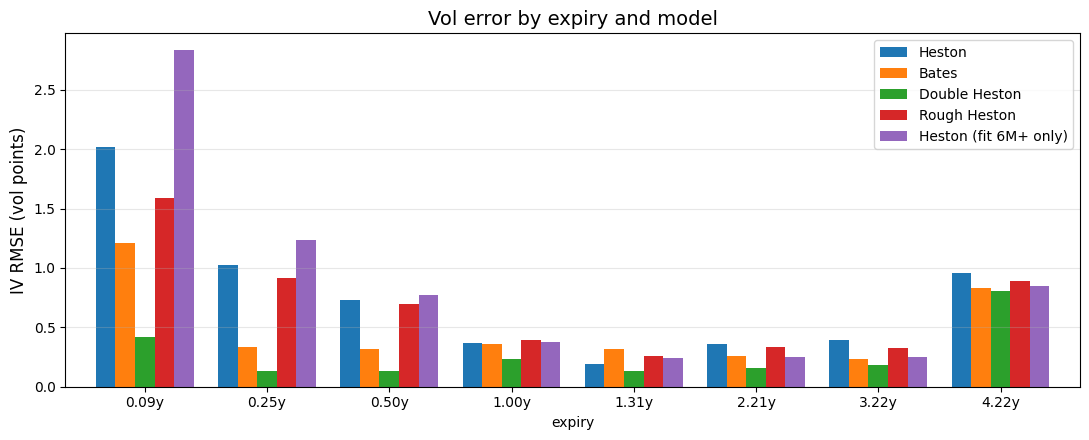

In [5]:
per_exp = pd.DataFrame({name: f['report'].set_index('T')['IV RMSE (vol pts)'] for name, f in fits.items()})
per_exp.index = [f"{t:.2f}y" if t != 'ALL' else 'ALL' for t in per_exp.index]
display(per_exp.round(3))
per_px = pd.DataFrame({name: f['report'].set_index('T')['price RMSE'] for name, f in fits.items()})
per_px.index = per_exp.index
print("Price RMSE (index points) per expiry:"); display(per_px.round(2))

fig, ax = plt.subplots(figsize=(11, 4.5))
per_exp.drop(index='ALL').plot.bar(ax=ax, width=0.8)
ax.set_ylabel('IV RMSE (vol points)', fontsize=12); ax.set_xlabel('expiry'); ax.set_title('Vol error by expiry and model', fontsize=14)
ax.grid(alpha=0.3, axis='y'); ax.legend(fontsize=10); plt.xticks(rotation=0); plt.tight_layout(); plt.show()


### 4.3 Smiles: market against every model
The short-dated slices are where the models differ; from 1Y on they all sit on top of each other and of the market, and the 4Y slice is limited by quote width (median bid-ask of 4 vol points).


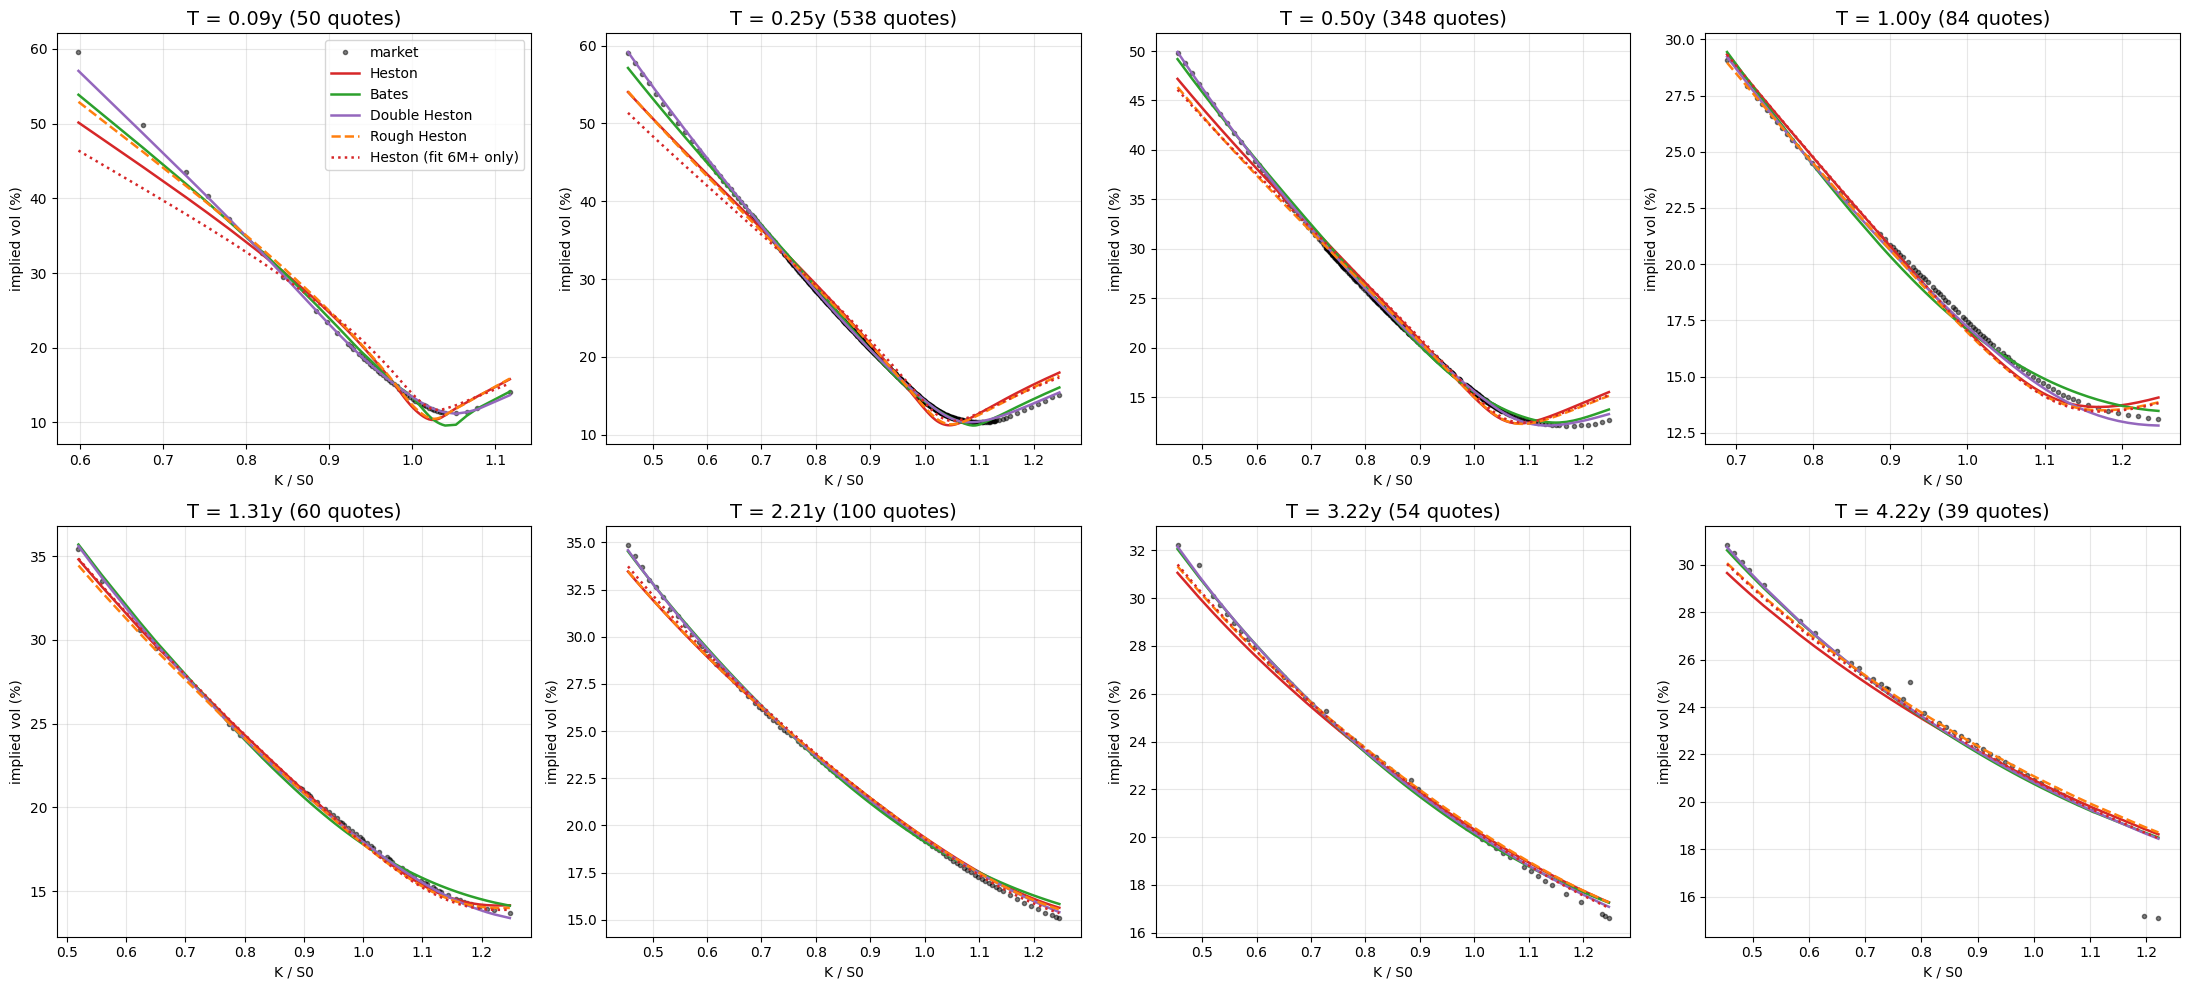

In [6]:
styles = {'Heston': ('tab:red', '-'), 'Bates': ('tab:green', '-'), 'Double Heston': ('tab:purple', '-'), 'Rough Heston': ('tab:orange', '--'), 'Heston (fit 6M+ only)': ('tab:red', ':')}
cal0 = fits['Heston']['cal']
n = len(cal0.data_batches); cols = 4; rws = (n + cols - 1) // cols
fig, axes = plt.subplots(rws, cols, figsize=(22, 5 * rws)); axes = axes.flatten()
for i, b in enumerate(cal0.data_batches):
    ax = axes[i]; m = cal0.flat_T == b['T']; rT = cal0.r_curve(b['T'])
    mon = b['strikes'] / S0
    ax.plot(mon, 100 * cal0.market_iv[m], 'ko', ms=3, alpha=0.5, label='market')
    for name, f in fits.items():
        iv = implied_vol_call_vec(f['cal'].price_calls(f['params'], b['T'], b['strikes'], b['q']), S0, b['strikes'], b['T'], rT, b['q'])
        c, ls = styles[name]; ax.plot(mon, 100 * iv, color=c, ls=ls, lw=1.8, label=name)
    ax.set_title(f"T = {b['T']:.2f}y ({m.sum()} quotes)", fontsize=14); ax.set_xlabel('K / S0'); ax.set_ylabel('implied vol (%)'); ax.grid(alpha=0.3)
    if i == 0: ax.legend(fontsize=10)
for j in range(i + 1, len(axes)): axes[j].axis('off')
plt.tight_layout(); plt.show()


## 5. What the model choice does to the note
Same 50,000 QE paths per model (daily steps, observation dates on the grid, seed 42), same payoff code as `main.ipynb`. Rough Heston is not priced (no simulation scheme here).


In [7]:
price_rows = []; van_rows = []
for name, mname in [('Heston', 'heston'), ('Bates', 'bates'), ('Double Heston', 'double_heston')]:
    f = fits[name]
    pr = MultiModelPricer(S0, S0, rate_curve_func, dividend_curve_func, f['params'], model=mname)
    pr.run_simulation(OBS_TIMES[-1], 252, 50000, obs_times=OBS_TIMES, seed=42, verbose=False)
    px = pr.price_structure(**PRODUCT_PARAMS, pricing_date=PRICING_DATE, verbose=False); oc = pr.outcomes
    price_rows.append({'model': name, 'price': px[0], 's.e.': pr.std_error, 'principal': px[1], 'coupons': px[2], 'put': px[3],
                       'P(call 1Y)': oc['call_prob_by_date'][0], 'P(KI)': oc['prob_knock_in'], 'E[level | KI]': oc['mean_perf_given_ki'],
                       'life (y)': oc['expected_life'], 'fair coupon @ par': pr.solve_fair_coupon(PRODUCT_PARAMS, 1000.0, pricing_date=PRICING_DATE)})
    mart = pr.martingale_check([1.0, OBS_TIMES[-1]])
    for T_chk in [OBS_TIMES[0], OBS_TIMES[-1]]:
        K = np.array([0.6, 0.8, 1.0]) * S0; tg = pr.time_grid[pr._get_time_index(T_chk)]
        mc, se = pr.mc_vanilla_calls(T_chk, K); fft = f['cal'].price_calls(f['params'], tg, K, dividend_curve_func(tg))
        for k, m_, s_, f_ in zip(K / S0, mc, se, fft):
            van_rows.append({'model': name, 'T': round(tg, 2), 'K/S0': k, 'MC': m_, 'FFT': f_, '(MC-FFT)/s.e.': (m_ - f_) / s_})
    print(f"{name:14s} martingale check E[S_t]/F(t)-1 at 1Y, 4Y: {mart['E[S_t]/F(t) - 1'].round(5).tolist()} (s.e. {mart['s.e.'].round(5).tolist()})")
pricing = pd.DataFrame(price_rows).set_index('model')
display(pricing.round(4))
print(f"Spread between models: {pricing['price'].max() - pricing['price'].min():.2f} per 1,000 (Monte Carlo s.e. about {pricing['s.e.'].mean():.2f})")
vanilla = pd.DataFrame(van_rows)
print(f"\nVanilla repricing, MC vs FFT: largest |MC-FFT| = {vanilla['(MC-FFT)/s.e.'].abs().max():.2f} standard errors")
display(vanilla.round(3))


Heston         martingale check E[S_t]/F(t)-1 at 1Y, 4Y: [-0.00078, -0.00131] (s.e. [0.0008, 0.0017])


Bates          martingale check E[S_t]/F(t)-1 at 1Y, 4Y: [-0.0005, 0.00196] (s.e. [0.0008, 0.00169])


Double Heston  martingale check E[S_t]/F(t)-1 at 1Y, 4Y: [0.00013, 0.00044] (s.e. [0.00079, 0.00166])


,price,s.e.,principal,coupons,put,P(call 1Y),P(KI),E[level | KI],life (y),fair coupon @ par
model,,,,,,,,,,
Heston,976.3644,0.6834,928.5887,71.8138,-24.0381,0.6982,0.0477,0.3834,1.5755,0.0399
Bates,975.8675,0.6978,926.8934,73.7056,-24.7315,0.6696,0.0479,0.3682,1.6114,0.0398
Double Heston,976.3612,0.6928,927.8983,72.8244,-24.3615,0.6862,0.0473,0.3703,1.5901,0.0397


Spread between models: 0.50 per 1,000 (Monte Carlo s.e. about 0.69)

Vanilla repricing, MC vs FFT: largest |MC-FFT| = 1.35 standard errors


,model,T,K/S0,MC,FFT,(MC-FFT)/s.e.
0,Heston,1.00,0.6,3285.453,3290.978,-0.984
1,Heston,1.00,0.8,1896.702,1902.469,-1.193
2,Heston,1.00,1.0,676.649,681.281,-1.345
3,Heston,4.01,0.6,3886.393,3894.142,-0.656
4,Heston,4.01,0.8,2807.256,2812.785,-0.514
5,Heston,4.01,1.0,1863.314,1865.822,-0.269
6,Bates,1.00,0.6,3291.479,3294.172,-0.485
7,Bates,1.00,0.8,1895.992,1897.415,-0.295
8,Bates,1.00,1.0,682.794,682.441,0.104
9,Bates,4.01,0.6,3916.664,3903.317,1.152


## 6. Conclusions

**Where Heston's error is.** 93% of Heston's squared vol error sits in the first six months (3M alone 55%, 1M 20%, 6M 18%). From 1Y to 3Y Heston is already at 0.19 to 0.39 vol points, which is inside the quote width. The 4.2Y slice (0.95 vol points) is quote noise rather than model error: its median bid-ask is 4 vol points and no model does better than 0.81 there.

**Error with and without the short end (Heston).** Fitted to all eight expiries: 0.90 vol points overall, 1.15 on 1M-3M, 0.61 on 6M+. Fitted to 6M+ only: 0.615 on 6M+ (no gain) and 1.44 on the short end out of sample. On this surface the short end costs Heston nothing at 6M+, so the extra expiries can stay in the fit; on the December 2025 surface they did cost about 0.2 vol points at 3Y-4Y, which is why `main.ipynb` fits 6M+ only. Price RMSE: 12.2 index points overall, 8.2 on the short end, 14.9 on 6M+, the latter driven by the 4.2Y slice (about 50 points for every model).

**What brings the errors down.**
- Double Heston is the best fit on every measure: 0.215 vol points overall (Heston 0.90), 0.17 on the short end, 0.245 on 6M+, price RMSE 8.9 (Heston 12.2), largest single miss 3.5 vol points (Heston 9.4). The fast factor does the short end ($\kappa_1=4.5$, $\sigma_1=3.7$, $V_{1,0}=0.007$), the slow factor the long end. The price is a 10-parameter search that differential evolution does not always converge (seed 42 gave 0.30, seed 7 gave 0.22), and extreme factor parameters that will move from day to day.
- Bates halves Heston's error (0.42 overall, 0.47 on the short end, price RMSE 9.9). The calibration pushes the jump intensity to its bound (5 jumps a year of $-4\%$, $\sigma_J$ at the floor); with $\lambda\le20$ it goes to 20 jumps of $-0.8\%$ for 0.41. The surface asks for a frequent-small-jump component rather than rare crashes, which is the signature of an infinite-activity Lévy part (variance gamma, CGMY) rather than Merton jumps.
- Rough Heston helps least here: 0.80 overall, with $H=0.33$, so the calibration does not want a very rough kernel on this snapshot. It is, with double Heston, the best model at the product strikes (0.13 vol points). Part of its residual may be approximant error: the (3,3) rational approximant is accurate to about $2\times10^{-3}$ in the characteristic function at $H\le0.1$ but $5\times10^{-3}$ at $H=0.3$, so a full numerical solve of the fractional Riccati would be needed to rule that out.

**What it does to the note.** The three priced models are within 0.5 per 1,000 of each other (976.4, 975.9, 976.4) with a Monte Carlo standard error of 0.7, and the fair coupon at par is 3.97% to 3.99% under all three. The note reads the surface at 1Y to 4Y and 60% to 100%, where every model agrees with the market to 0.13 to 0.21 vol points, so the fit gains at 1M and 3M do not reach the price. The model difference that would matter for the note is in the forward skew and the path behaviour, and these three models give the same answer within noise.

**Recommendation.** For pricing this note, Heston fitted to 6M+ is adequate and the most stable. For a fit of the whole surface, double Heston or Bates, with the caveats above: run at least two optimiser seeds for double Heston, and expect the Bates jump intensity to sit on its bound. If a product observed the index inside the first six months (a 3M autocall, a daily knock-in), the Heston short-end error of 1 to 2 vol points would matter and Bates or double Heston should be used. Two limits of this study: one snapshot, and a Treasury curve standing in for SOFR OIS (which affects discounting, not the surface fit).
